# Next-Week Delay Forecasting: Summary
- **What we tried:** predict **next week's** `shipping_delay_days` for each route instead of this week's `route_status`, then turn the predicted delay into a status with the business rule (Normal < 5 ≤ Delayed < 12 ≤ Disrupted days). 4 models: LightGBM and Linear Regression, each on feature set A (7 features) and B (19 features).
- **What we got:** every model predicts about the training mean (≈ 6.3 days) for every route-week (R² ≈ 0), so every prediction maps to Delayed and no Disrupted week is caught.
- **Why we believe it doesn't work:** in this data, nothing about a route's week *t*, not even its own delay, carries over to week *t + 1*. The same features predict the *same* week's delay well, so the features are fine; the next week is simply not predictable from them.

## 1. What We Tried
**The label.** One row = one route at week *t*. The features are known at the end of week *t*; the label is the same route's `shipping_delay_days` in week *t + 1*. A predicted delay is turned into a status with the business rule: Normal < 5 days, Delayed 5 to < 12 days, Disrupted ≥ 12 days.

**The split.** Chronological: train = target weeks before 2024-08-11, test = from 2024-08-11. In the last 30 test weeks (from 2026-06-07) delays are much higher (see the Disrupted shares below), so the test weeks are scored in two parts.

| | What it is |
|---|---|
| **Feature set A** | 7 features at week *t*: port congestion, weather, geopolitical risk, origin and destination event risk, COVID flag, Russia-Ukraine war flag |
| **Feature set B** | A + 12 history features: last week, change since last week, 4-week mean and 4-week max of port congestion, weather and geopolitical risk (19 total) |
| **LightGBM** | fixed settings; the number of trees is chosen by early stopping on the last 20% of training weeks, then the model is refit on all training rows |
| **Linear Regression** | standardized features (mean 0, SD 1 on the training rows), ordinary least squares |

The cell below loads the dataset, checks the label against the raw weekly file, and shows the split sizes.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor, early_stopping
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 200)

TARGET = "target_delay_next_week"
SHIFT_START = pd.Timestamp("2026-06-07")   # first target week of the last 30 test weeks
DELAYED_FROM, DISRUPTED_FROM = 5.0, 12.0   # Normal < 5 <= Delayed < 12 <= Disrupted (days)
FEATURES_A = ["geopolitical_risk_score", "port_congestion_index", "weather_disruption_score",
              "origin_active_event_risk", "destination_active_event_risk",
              "covid_supply_shock_active", "russia_ukraine_war_active"]
SIGNALS = ["port_congestion_index", "weather_disruption_score", "geopolitical_risk_score"]
FEATURES_B = FEATURES_A + [f"{s}_{k}" for s in SIGNALS for k in ["lag1", "delta1", "roll4_mean", "roll4_max"]]

NAMES = {"geopolitical_risk_score": "Geopolitical risk", "port_congestion_index": "Port congestion",
         "weather_disruption_score": "Weather disruption", "origin_active_event_risk": "Origin event risk",
         "destination_active_event_risk": "Destination event risk", "covid_supply_shock_active": "COVID flag",
         "russia_ukraine_war_active": "Russia-Ukraine war flag"}
SUFFIXES = {"_lag1": ": last week", "_delta1": ": change since last week",
            "_roll4_mean": ": 4-week mean", "_roll4_max": ": 4-week max"}


def readable(col):   # 'port_congestion_index_roll4_max' -> 'Port congestion: 4-week max'
    for suffix, text in SUFFIXES.items():
        if col.endswith(suffix):
            return NAMES[col[:-len(suffix)]] + text
    return NAMES.get(col, col)


def delay_to_status(delay):   # business rule; a boundary belongs to the higher status
    delay = np.asarray(delay, dtype=float)
    return np.select([delay < DELAYED_FROM, delay < DISRUPTED_FROM], ["Normal", "Delayed"], "Disrupted").astype(object)


def tidy(table, decimals=4):   # round the numeric columns (and turn -0.0 into 0.0) for display
    numbers = table.select_dtypes("number").columns
    return table.assign(**{c: table[c].round(decimals) + 0.0 for c in numbers})


df = pd.read_csv("../data/preprocessed/next_week_delay_dataset.csv")
for col in ["date", "target_date"]:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y")
df = df.sort_values(["route_id", "date"]).reset_index(drop=True)

# Raw weekly file: each route's actual delay per week ('R00007' -> 'R7', as in the dataset)
raw = pd.read_csv("../data/weekly_route_operations.csv")
raw["date"] = pd.to_datetime(raw["date"], format="%m/%d/%Y")
raw["route_id"] = "R" + raw["route_id"].str[1:].astype(int).astype(str)
delay_by_week = raw.set_index(["route_id", "date"])["shipping_delay_days"]
lookup = lambda dates: delay_by_week.reindex(pd.MultiIndex.from_arrays([df["route_id"], dates])).to_numpy()
df["delay_same_week"] = lookup(df["date"])   # week t's own delay: used only for the contrast in section 3

assert (df["target_date"] - df["date"]).eq(pd.Timedelta(days=7)).all()                 # label week = week t + 7 days
assert np.allclose(df[TARGET], lookup(df["target_date"]))                              # label = raw delay of that week
assert (delay_to_status(df[TARGET]) == df["target_status_next_week"].to_numpy()).all()  # status = business rule
assert df["delay_same_week"].notna().all()

train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
before = (test["target_date"] < SHIFT_START).to_numpy()   # test target weeks before 2026-06-07
y = test[TARGET].to_numpy()

span = lambda d: f"{d['target_date'].min():%Y-%m-%d} to {d['target_date'].max():%Y-%m-%d}"
disrupted = lambda v: f"{100 * (np.asarray(v) >= DISRUPTED_FROM).mean():.1f}% Disrupted"
print(f"{len(df):,} rows ({df['route_id'].nunique()} routes) = train {len(train):,} (target weeks {span(train)}) "
      f"+ test {len(test):,} ({span(test)})")
print("Checks passed on every row: label week = week t + 7 days; label = raw delay of that week; status = 5/12 rule")
print(f"Train: {disrupted(train[TARGET])} | test before 2026-06-07: {before.sum():,} rows, {disrupted(y[before])} | "
      f"last 30 test weeks: {(~before).sum():,} rows, {disrupted(y[~before])}")

show = {"date": "Week t", "route_id": "Route", "target_date": "Label week (t+1)", TARGET: "Next-week delay (days)",
        "port_congestion_index": "Port congestion (t)", "weather_disruption_score": "Weather (t)",
        "geopolitical_risk_score": "Geopolitical risk (t)"}
df[list(show)].head(3).rename(columns=show)

31,200 rows (50 routes) = train 24,950 (target weeks 2015-01-18 to 2024-08-04) + test 6,250 (2024-08-11 to 2026-12-27)
Checks passed on every row: label week = week t + 7 days; label = raw delay of that week; status = 5/12 rule
Train: 2.5% Disrupted | test before 2026-06-07: 4,750 rows, 2.1% Disrupted | last 30 test weeks: 1,500 rows, 18.7% Disrupted


,Week t,Route,Label week (t+1),Next-week delay (days),Port congestion (t),Weather (t),Geopolitical risk (t)
0,2015-01-11,R1,2015-01-18,3.67,72.01,91.27,41.47
1,2015-01-18,R1,2015-01-25,9.22,44.64,46.69,79.69
2,2015-01-25,R1,2015-02-01,6.36,97.82,56.39,67.15


In [2]:
LGBM_PARAMS = {"objective": "regression", "n_estimators": 2000, "learning_rate": 0.03, "num_leaves": 15,
               "min_child_samples": 50, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8,
               "reg_lambda": 1.0, "random_state": 42, "n_jobs": -1, "deterministic": True, "force_row_wise": True,
               "verbose": -1}


def fit_lightgbm(features):
    """Early stopping (patience 100 trees) on the last 20% of training target weeks, then refit on all training rows."""
    weeks = np.sort(train["target_date"].unique())
    is_valid = train["target_date"] >= weeks[int(0.8 * len(weeks))]
    fit_part, valid_part = train[~is_valid], train[is_valid]
    with warnings.catch_warnings():   # newer LightGBM renames eval_set; the old name still works
        warnings.filterwarnings("ignore", message=".*eval_set.*deprecated.*")
        probe = LGBMRegressor(**LGBM_PARAMS).fit(fit_part[features], fit_part[TARGET], eval_metric="l2",
                                                 eval_set=[(valid_part[features], valid_part[TARGET])],
                                                 callbacks=[early_stopping(100, verbose=False)])
    n_trees = int(max(probe.best_iteration_, 1))
    return LGBMRegressor(**{**LGBM_PARAMS, "n_estimators": n_trees}).fit(train[features], train[TARGET]), n_trees


def fit_linear(features, label):
    return make_pipeline(StandardScaler(), LinearRegression()).fit(train[features], label)


preds, trees, linear = {"Training mean (baseline)": np.full(len(test), train[TARGET].mean())}, {}, {}
for set_name, features in [("A", FEATURES_A), ("B", FEATURES_B)]:
    model, trees[f"LightGBM {set_name}"] = fit_lightgbm(features)
    preds[f"LightGBM {set_name}"] = model.predict(test[features])
for set_name, features in [("A", FEATURES_A), ("B", FEATURES_B)]:
    linear[set_name] = fit_linear(features, train[TARGET])
    preds[f"Linear {set_name}"] = linear[set_name].predict(test[features])
print(f"Training mean = {train[TARGET].mean():.3f} days | LightGBM trees chosen by early stopping "
      f"(upper limit 2000): {trees}")

Training mean = 6.279 days | LightGBM trees chosen by early stopping (upper limit 2000): {'LightGBM A': 1, 'LightGBM B': 3}


## 2. What We Got
Scores on the test weeks, in two parts. *Disrupted recall* = share of true Disrupted weeks (≥ 12 days) that the model calls Disrupted. The baseline predicts the training mean for every row.

In [3]:
def summary(mask):
    rows = []
    for name, pred in preds.items():
        p, status = pred[mask], delay_to_status(pred[mask])
        rows.append({"Model": name, "MAE (days)": mean_absolute_error(y[mask], p), "R²": r2_score(y[mask], p),
                     "Predicted delay (days)": f"{p.min():.2f} to {p.max():.2f}",
                     "% predicted Delayed": 100 * (status == "Delayed").mean(),
                     "Disrupted recall": (status[y[mask] >= DISRUPTED_FROM] == "Disrupted").mean()})
    return tidy(pd.DataFrame(rows).set_index("Model"))


for label, mask in [("Test weeks before 2026-06-07", before), ("Last 30 test weeks (high-delay period)", ~before)]:
    print(f"\n{label}: {mask.sum():,} rows, actual delay {y[mask].min():.2f} to {y[mask].max():.2f} days, "
          f"{disrupted(y[mask])}")
    display(summary(mask))


Test weeks before 2026-06-07: 4,750 rows, actual delay 0.00 to 16.70 days, 2.1% Disrupted


,MAE (days),R²,Predicted delay (days),% predicted Delayed,Disrupted recall
Model,,,,,
Training mean (baseline),2.3253,0.0000,6.28 to 6.28,100.0,0.0
LightGBM A,2.3253,0.0000,6.26 to 6.29,100.0,0.0
LightGBM B,2.3257,-0.0002,6.25 to 6.37,100.0,0.0
Linear A,2.3251,-0.0001,6.18 to 6.37,100.0,0.0
Linear B,2.3260,-0.0011,5.99 to 6.53,100.0,0.0



Last 30 test weeks (high-delay period): 1,500 rows, actual delay 0.00 to 20.95 days, 18.7% Disrupted


,MAE (days),R²,Predicted delay (days),% predicted Delayed,Disrupted recall
Model,,,,,
Training mean (baseline),3.5139,-0.3295,6.28 to 6.28,100.0,0.0
LightGBM A,3.5147,-0.3300,6.26 to 6.32,100.0,0.0
LightGBM B,3.5137,-0.3293,6.26 to 6.33,100.0,0.0
Linear A,3.5103,-0.3267,6.17 to 6.38,100.0,0.0
Linear B,3.5251,-0.3357,5.98 to 6.46,100.0,0.0


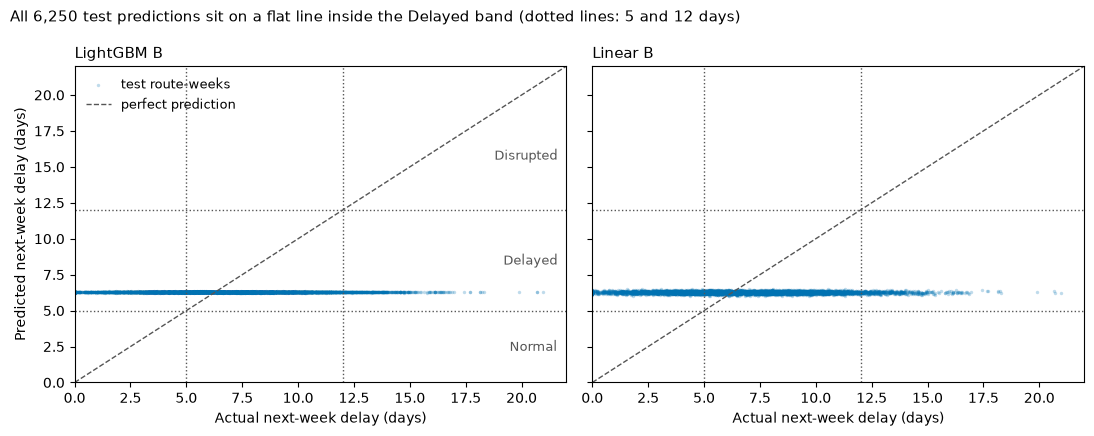

In [4]:
BLUE, GREY = "#0072B2", "#555555"   # Okabe-Ito blue: colorblind-safe
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
lim = (0, np.ceil(y.max()) + 1)
for ax, name in zip(axes, ["LightGBM B", "Linear B"]):
    ax.scatter(y, preds[name], s=6, alpha=0.25, color=BLUE, linewidths=0, label="test route-weeks")
    ax.plot(lim, lim, "--", color=GREY, linewidth=1, label="perfect prediction")
    for cut in (DELAYED_FROM, DISRUPTED_FROM):
        ax.axhline(cut, color=GREY, linestyle=":", linewidth=1)
        ax.axvline(cut, color=GREY, linestyle=":", linewidth=1)
    ax.set(xlim=lim, ylim=lim, xlabel="Actual next-week delay (days)")
    ax.set_title(name, loc="left", fontsize=11)
for y_text, text in [(2.2, "Normal"), (8.2, "Delayed"), (15.5, "Disrupted")]:
    axes[0].text(lim[1] - 0.4, y_text, text, ha="right", fontsize=9, color=GREY)
axes[0].set_ylabel("Predicted next-week delay (days)")
axes[0].legend(loc="upper left", frameon=False, fontsize=9)
fig.suptitle(f"All {len(test):,} test predictions sit on a flat line inside the Delayed band "
             "(dotted lines: 5 and 12 days)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

- **All 4 models ≈ the training mean.** Before 2026-06-07: MAE 2.3251 to 2.3260 days vs. 2.3253 for always predicting 6.28 days; R² between −0.0011 and 0.0000. Early stopping kept only 1 (A) and 3 (B) LightGBM trees: more trees never helped on the validation weeks. History features (B) are no better than A.
- **Every prediction lies between 5.98 and 6.53 days**, inside the Delayed band (5 to 12), so 100% of route-weeks are called Delayed and Disrupted recall is 0 in both parts. In the figure, a useful forecast would follow the dashed diagonal; instead actual delays from 0 to 21 days all get the same prediction.
- **Last 30 weeks:** delays jump (18.7% Disrupted) and every model scores R² ≈ −0.33, the same as the training mean: nothing in the features anticipates the jump.

## 3. Why We Believe It Doesn't Work
### 3a. Intercept vs. coefficients
With standardized features, the Linear Regression **intercept** is the prediction for an average route-week (every feature at its training mean), and each **coefficient** is the days of predicted delay per 1 SD of a feature. We compare the two next-week fits from section 1 with a **same-week** fit: same rows and features A, but the label is week *t*'s own delay (from the raw weekly file).

In [5]:
SETUPS = {"Next week, A (7 features)": (FEATURES_A, TARGET, linear["A"]),
          "Next week, B (19 features)": (FEATURES_B, TARGET, linear["B"]),
          "Same week, A (7 features)": (FEATURES_A, "delay_same_week", fit_linear(FEATURES_A, train["delay_same_week"]))}
rows, coefs = [], {}
for name, (features, label, fit) in SETUPS.items():
    ols, pred = fit[-1], fit.predict(test[features])
    coefs[name] = pd.Series(ols.coef_, index=features)
    top = coefs[name].abs().idxmax()
    rows.append({"Model": name, "Intercept (days)": ols.intercept_, "Training-mean delay (days)": train[label].mean(),
                 "Largest |coef| (days per SD)": abs(coefs[name][top]), "Largest-coef feature": readable(top),
                 "Test predictions (days)": f"{pred[before].min():.2f} to {pred[before].max():.2f}",
                 "Test prediction SD (days)": pred[before].std(),
                 "Test R²": r2_score(test.loc[before, label], pred[before])})
print("Test columns: target weeks before 2026-06-07. Label SD on training rows: "
      f"next week {train[TARGET].std():.2f} days, same week {train['delay_same_week'].std():.2f} days")
tidy(pd.DataFrame(rows).set_index("Model"))

Test columns: target weeks before 2026-06-07. Label SD on training rows: next week 2.88 days, same week 2.88 days


,Intercept (days),Training-mean delay (days),Largest |coef| (days per SD),Largest-coef feature,Test predictions (days),Test prediction SD (days),Test R²
Model,,,,,,,
"Next week, A (7 features)",6.2788,6.2788,0.0379,Origin event risk,6.18 to 6.37,0.0327,-0.0001
"Next week, B (19 features)",6.2788,6.2788,0.0465,Port congestion: 4-week max,5.99 to 6.53,0.0704,-0.0011
"Same week, A (7 features)",6.2765,6.2765,1.4367,Geopolitical risk,0.59 to 12.26,2.1171,0.5353


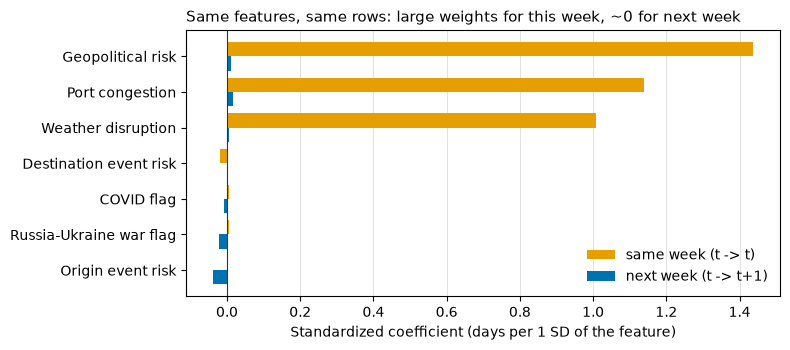

Same week, A (7 features), top 3 (days per SD): Geopolitical risk +1.44, Port congestion +1.14, Weather disruption +1.01
Next week, A (7 features), top 3 (days per SD): Origin event risk -0.04, Russia-Ukraine war flag -0.02, Port congestion +0.02


In [6]:
ORANGE = "#E69F00"   # Okabe-Ito orange, next to BLUE: colorblind-safe pair
order = coefs["Same week, A (7 features)"].abs().sort_values().index
pos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(pos + 0.2, coefs["Same week, A (7 features)"][order], height=0.4, color=ORANGE, label="same week (t -> t)")
ax.barh(pos - 0.2, coefs["Next week, A (7 features)"][order], height=0.4, color=BLUE, label="next week (t -> t+1)")
ax.set_yticks(pos, [readable(f) for f in order])
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Standardized coefficient (days per 1 SD of the feature)")
ax.set_title("Same features, same rows: large weights for this week, ~0 for next week", loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", color="#dddddd", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
for name in ["Same week, A (7 features)", "Next week, A (7 features)"]:
    top3 = coefs[name].reindex(coefs[name].abs().sort_values(ascending=False).index[:3])
    print(f"{name}, top 3 (days per SD):", ", ".join(f"{readable(f)} {v:+.2f}" for f, v in top3.items()))

- **The intercept equals the training mean in every row** (6.28 days). The difference between the rows is entirely in the coefficients.
- **Next week:** the largest coefficient is 0.04 to 0.05 days per SD (label SD 2.88 days), so test predictions vary by only 0.03 to 0.07 days (SD) around the intercept. Every prediction is essentially the intercept, and test R² ≈ 0.
- **Same week:** geopolitical risk (+1.44), port congestion (+1.14) and weather (+1.01 days per SD) spread predictions from 0.59 to 12.26 days, with test R² 0.54. The features are linked to delay correctly, but only to the week they describe.

### 3b. Does anything at week *t* carry over to week *t + 1*?
Checked on the raw weekly file, weeks before 2026-06-07 (the last 30 weeks shift up as a block, which would fake a week-to-week link). Then a **shuffled-label control**: refit the next-week Linear Regression 100 times on randomly shuffled training labels, which have no link to the features by construction, and compare with the real fit.

In [7]:
stable = raw[raw["date"] < SHIFT_START].sort_values(["route_id", "date"])
autocorr = pd.DataFrame({f"lag {k}": stable.groupby("route_id")["shipping_delay_days"].apply(lambda s: s.autocorr(k))
                         for k in (1, 2, 4, 52)})
print("Delay autocorrelation per route (50 routes), mean [min to max]:  " + " | ".join(
    f"{c} {autocorr[c].mean():+.4f} [{autocorr[c].min():+.3f} to {autocorr[c].max():+.3f}]" for c in autocorr))

numeric = stable.select_dtypes("number").columns
delay_next = stable.groupby("route_id")["shipping_delay_days"].shift(-1)
has_next = delay_next.notna()
corr_next = stable.loc[has_next, numeric].corrwith(delay_next[has_next])
corr_same = stable.loc[has_next, numeric].corrwith(stable.loc[has_next, "shipping_delay_days"]).drop("shipping_delay_days")
print(f"Each of the {len(numeric)} raw columns at week t vs. delay at t+1: largest |correlation| = "
      f"{corr_next.abs().max():.4f} ({corr_next.abs().idxmax()})")
print(f"Same columns vs. delay in the SAME week: largest |correlation| = {corr_same.abs().max():.2f} "
      f"({corr_same.abs().idxmax()})")

rng = np.random.default_rng(42)
rows = []
for set_name, features in [("A", FEATURES_A), ("B", FEATURES_B)]:
    shuffled = []
    for _ in range(100):
        fit = fit_linear(features, rng.permutation(train[TARGET].to_numpy()))
        shuffled.append((np.abs(fit[-1].coef_).max(), r2_score(y[before], fit.predict(test.loc[before, features]))))
    shuffled = np.array(shuffled)
    rows.append({"Linear": set_name, "Real: largest |coef|": np.abs(linear[set_name][-1].coef_).max(),
                 "Shuffled: largest |coef|, 5th to 95th pct": "{:.4f} to {:.4f}".format(*np.percentile(shuffled[:, 0], [5, 95])),
                 "Real: test R²": r2_score(y[before], preds[f"Linear {set_name}"][before]),
                 "Shuffled: test R², 5th to 95th pct": "{:.4f} to {:.4f}".format(*np.percentile(shuffled[:, 1], [5, 95]))})
print("\nShuffled-label control (100 shuffles; test weeks before 2026-06-07):")
tidy(pd.DataFrame(rows).set_index("Linear"))

Delay autocorrelation per route (50 routes), mean [min to max]:  lag 1 +0.0027 [-0.084 to +0.100] | lag 2 -0.0052 [-0.131 to +0.098] | lag 4 -0.0011 [-0.088 to +0.106] | lag 52 -0.0095 [-0.091 to +0.082]
Each of the 10 raw columns at week t vs. delay at t+1: largest |correlation| = 0.0057 (port_congestion_index)
Same columns vs. delay in the SAME week: largest |correlation| = 0.50 (container_availability_index)



Shuffled-label control (100 shuffles; test weeks before 2026-06-07):


,Real: largest |coef|,"Shuffled: largest |coef|, 5th to 95th pct",Real: test R²,"Shuffled: test R², 5th to 95th pct"
Linear,,,,
A,0.0379,0.0171 to 0.0554,-0.0001,-0.0006 to 0.0000
B,0.0465,0.0299 to 0.0793,-0.0011,-0.0014 to 0.0001


- **Delay has no memory:** a route's delay this week vs. next week has autocorrelation +0.003 on average, and it stays within ±0.01 at 2, 4 and 52 weeks.
- **No column at week *t* relates to next week's delay:** every raw column is within ±0.006 of zero correlation with the delay at *t + 1*, while the same columns reach ±0.50 with the same week's delay.
- **The real next-week fit looks like a fit to random labels:** the largest real coefficient (0.038 for A, 0.047 for B) falls inside the 5th-to-95th-percentile range of fits to shuffled labels (0.017 to 0.055 for A, 0.030 to 0.079 for B), and so does the real test R² (−0.0001 vs. −0.0006 to 0.0000 for A; −0.0011 vs. −0.0014 to 0.0001 for B).
- **So the data behaves as if each week is drawn independently:** the drivers of delay (risk, congestion, weather) and the delay itself are redrawn every week, and the best possible next-week prediction is the average, which is exactly what all 4 models learned. This is a property of the data, not of the models.

## Takeaway
- **Forecasting next week's delay (and so next week's status) is not supported by this data.** All 4 models collapse to the training mean, and the checks above show there is no week-to-week link for any model to find.
- **The signal is in the same week:** week-*t* features explain about half of week *t*'s delay (R² 0.54).
- **A real next-week forecast needs information about week *t + 1* that is already known at week *t*** (e.g. scheduled events, weather or congestion forecasts, booked volumes). These files contain none.